# Praktikum 1

In [1]:
# Load data
import pandas as pd
raw_data = pd.read_csv('burnout_dataset1.csv')
fitur_utama = ['Anxiety_Score', 'Depression_Score', 'Mood_Score', 'Productivity_Score']
data = raw_data[fitur_utama + ['Burnout_Risk']].copy()
data[fitur_utama] = data[fitur_utama].fillna(data[fitur_utama].median())
data.head()

,Anxiety_Score,Depression_Score,Mood_Score,Productivity_Score,Burnout_Risk
0,74.0,75.0,26.0,19.0,High
1,58.0,80.0,29.0,27.0,Moderate
2,54.0,55.0,44.0,51.0,Moderate
3,12.0,11.0,88.0,83.0,Low
4,25.0,48.0,67.0,61.0,Low


In [2]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 5 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Anxiety_Score       50000 non-null  float64
 1   Depression_Score    50000 non-null  float64
 2   Mood_Score          50000 non-null  float64
 3   Productivity_Score  50000 non-null  float64
 4   Burnout_Risk        50000 non-null  str    
dtypes: float64(4), str(1)
memory usage: 2.1 MB


In [3]:
data.describe()

,Anxiety_Score,Depression_Score,Mood_Score,Productivity_Score
count,50000.000000,50000.000000,50000.000000,50000.000000
mean,40.425860,40.573940,59.647780,59.473740
std,25.796054,26.085165,25.551032,25.781175
min,0.000000,0.000000,0.000000,0.000000
25%,20.000000,20.000000,42.000000,41.000000
50%,39.000000,39.000000,61.000000,61.000000
75%,59.000000,59.000000,80.000000,80.000000
max,100.000000,100.000000,100.000000,100.000000


In [4]:
data['Burnout_Risk'].value_counts()

Burnout_Risk
Low         25369
Moderate    14780
High         9851
Name: count, dtype: int64

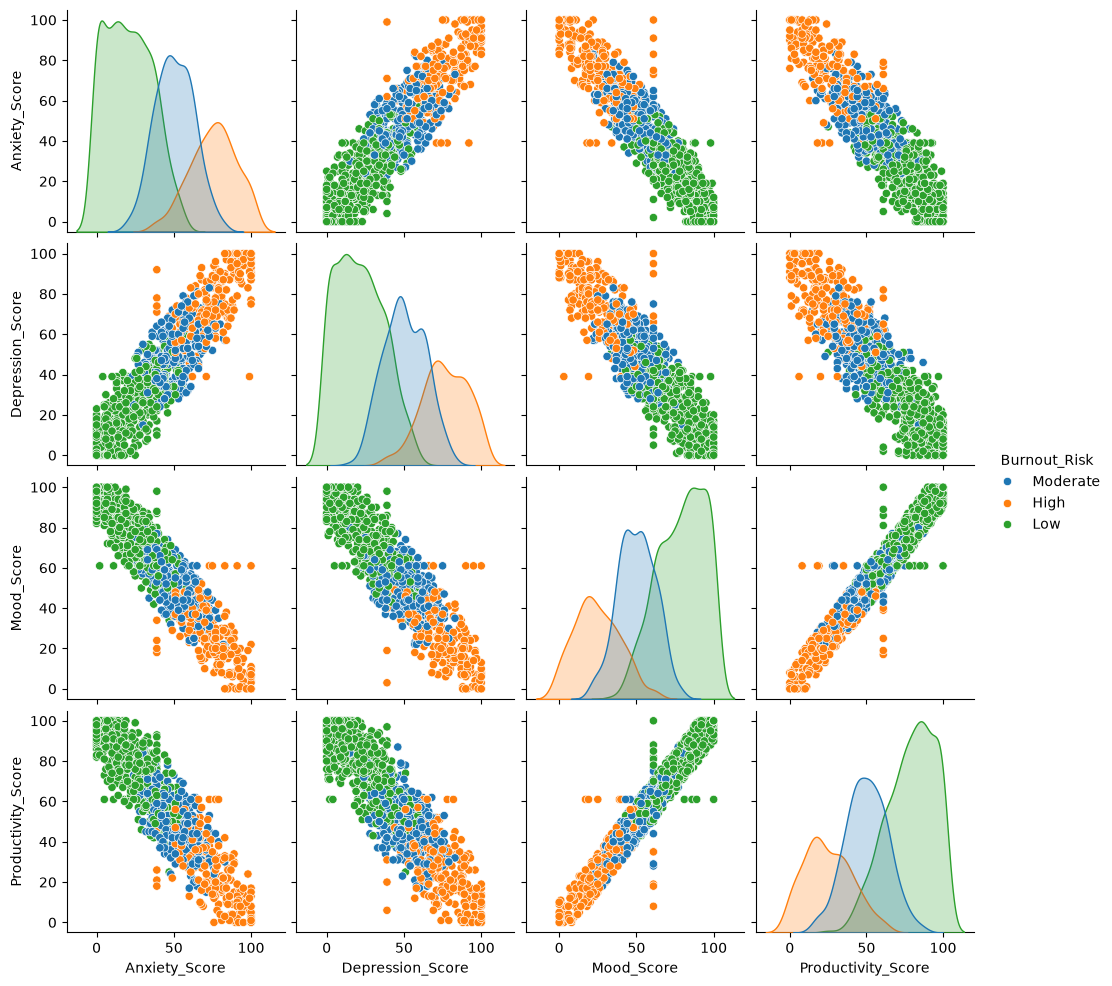

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# Gunakan sampel 1000 baris agar visualisasi pairplot jelas dan rapi
sns.pairplot(data.sample(n=1000, random_state=42), hue='Burnout_Risk')
plt.show()

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = data.iloc[:, :-1]   # semua kolom fitur terpilih
y = data.iloc[:, -1]    # kolom label Burnout_Risk

# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standardisasi
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [7]:
from sklearn.neighbors import KNeighborsClassifier

# Tentukan nilai K (misalnya 3)
knn = KNeighborsClassifier(n_neighbors=3)

# Latih model
knn.fit(X_train, y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",3
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[object](3,)","['High','Low','Moderate']"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [8]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = knn.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 0.7772
Confusion Matrix:
 [[2194    3  738]
 [  21 6712  937]
 [ 691  952 2752]]


Laporan Klasifikasi:
               precision    recall  f1-score   support

        High       0.75      0.75      0.75      2935
         Low       0.88      0.88      0.88      7670
    Moderate       0.62      0.63      0.62      4395

    accuracy                           0.78     15000
   macro avg       0.75      0.75      0.75     15000
weighted avg       0.78      0.78      0.78     15000



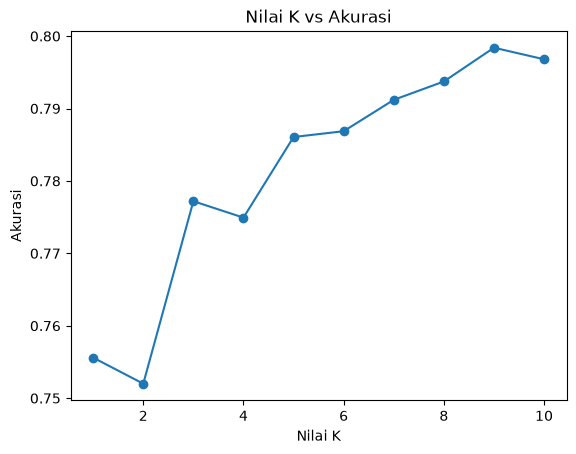

In [9]:
acc = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc.append(model.score(X_test, y_test))

plt.plot(range(1, 11), acc, marker='o')
plt.title('Nilai K vs Akurasi')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.show()

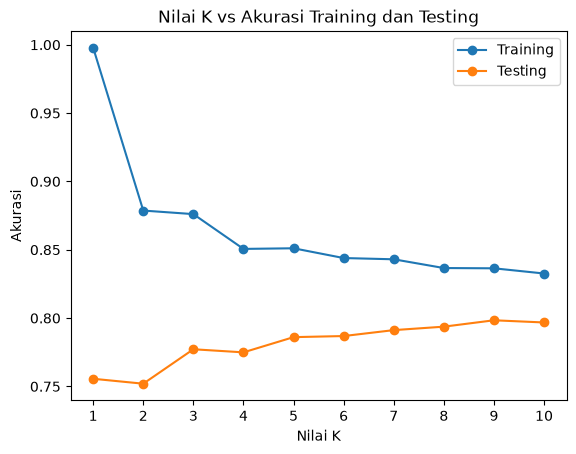

In [10]:
acc_train = []
for k in range(1, 11):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train, y_train)
    acc_train.append(model.score(X_train, y_train))

plt.plot(range(1, 11), acc_train, marker='o', label='Training')
plt.plot(range(1, 11), acc, marker='o', label='Testing')
plt.title('Nilai K vs Akurasi Training dan Testing')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.xticks(range(1, 11))
plt.legend()
plt.show()